In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [2]:
df=pd.read_csv('height-weight.csv')

In [3]:
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,163
3,60,175
4,70,160


Text(0, 0.5, 'Height')

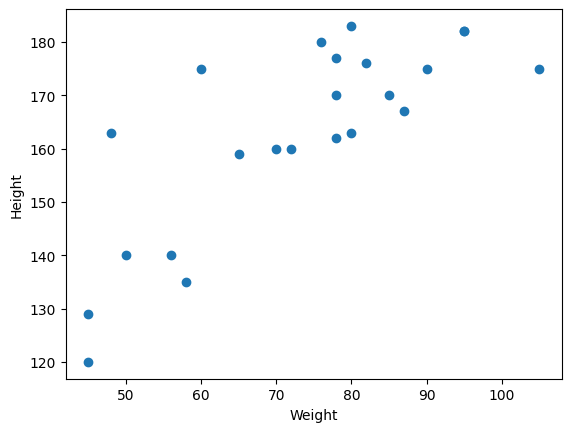

In [4]:
##scatter plot
plt.scatter(df['Weight'],df['Height'])
plt.xlabel("Weight")
plt.ylabel("Height")

In [5]:
## Correlation
df.corr()

,Weight,Height
Weight,1.000000,0.791134
Height,0.791134,1.000000


In [6]:
df.corr()


,Weight,Height
Weight,1.000000,0.791134
Height,0.791134,1.000000


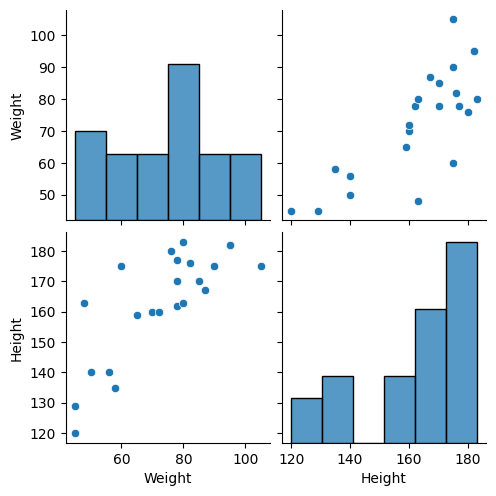

In [7]:
## Seaborn for visualization
import seaborn as sns
sns.pairplot(df)

In [8]:
## Independent and dependent features
X=df[['Weight']] ### independent features should be data frame or 2 dimesnionalarray
y=df['Height'] ## this variiable can be in series or 1d array


In [9]:
X_series=df['Weight']
np.array(X_series).shape

(23,)

In [10]:
np.array(y).shape

(23,)

In [11]:
## Train Test Split
from sklearn.model_selection import train_test_split


In [12]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [13]:
## Standardization
from sklearn.preprocessing import StandardScaler

In [14]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)


In [15]:
X_test=scaler.transform(X_test) #for the test data we should not fit the scaler again, we should use the same scaler which is fitted on the training data
#we dont want to leak any information from the test data to the training data

In [16]:
X_test

array([[ 0.44231255],
       [ 0.44231255],
       [-1.73433079],
       [ 1.56361367],
       [-0.41515301],
       [ 2.22320256]])

In [17]:
## Apply Simple Linear Regression
from sklearn.linear_model import LinearRegression

In [18]:
regression=LinearRegression(n_jobs=-1)

In [19]:
regression.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,-1
,positive,False


In [20]:
print("Coefficient or slope:",regression.coef_)
print("Intercept:",regression.intercept_)

Coefficient or slope: [12.39342422]
Intercept: 162.35294117647058


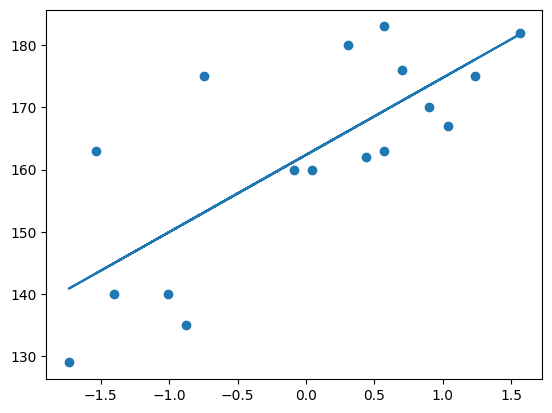

In [21]:
## plot Training data plot best fit line
plt.scatter(X_train,y_train)
plt.plot(X_train,regression.predict(X_train))

### prediction of test data
1. predicted height output= intercept +coef_(Weights)
2. y_pred_test =156.470 + 17.29(X_test)

In [22]:
## Prediction for test data
y_pred=regression.predict(X_test)

In [23]:
## Performance Metrics
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [24]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

124.87468495919536
8.192669757732682
11.174734223201703


## R square 
Formula

**R^2 = 1 - SSR/SST**


R^2	=	coefficient of determination
SSR	=	sum of squares of residuals
SST	=	total sum of squares

In [25]:
from sklearn.metrics import r2_score

In [26]:
score=r2_score(y_test,y_pred)
print(score)

0.71302338598589


**Adjusted R2 = 1 – [(1-R2)*(n-1)/(n-k-1)]**

where:

R2: The R2 of the model
n: The number of observations
k: The number of predictor variables

In [27]:
#display adjusted R-squared
1 - (1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.6412792324823625

In [28]:
## OLS Linear Regression
import statsmodels.api as sm

In [29]:
model=sm.OLS(y_train,X_train).fit()

In [30]:
prediction=model.predict(X_test)
print(prediction)

[  5.48176708   5.48176708 -21.49429723  19.37852748  -5.14516735
  27.55309242]


In [31]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                 Height   R-squared (uncentered):                   0.006
Model:                            OLS   Adj. R-squared (uncentered):             -0.056
Method:                 Least Squares   F-statistic:                            0.09283
Date:                Wed, 20 May 2026   Prob (F-statistic):                       0.765
Time:                        18:14:39   Log-Likelihood:                         -110.69
No. Observations:                  17   AIC:                                      223.4
Df Residuals:                      16   BIC:                                      224.2
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

c:\Users\jashw\anaconda3\envs\ml_env\lib\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=17 observations were given.
  return hypotest_fun_in(*args, **kwds)


In [32]:
## Prediction For new data
regression.predict(scaler.transform([[72]]))
##when we have new data we should also scale it using the same scaler which is fitted on the training data

c:\Users\jashw\anaconda3\envs\ml_env\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([162.92996929])

In [33]:
regression.predict(scaler.transform([[85]]))

c:\Users\jashw\anaconda3\envs\ml_env\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([173.55690372])